In [473]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler, OneHotEncoder, PolynomialFeatures
from sklearn.model_selection import train_test_split
import re
from sklearn.ensemble import RandomForestRegressor

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import pickle

In [474]:
df = pd.read_csv("https://drive.google.com/uc?export=download&id=1D5gl2EZtevQCf9AgRR3MWtkmOefu_qnd")

In [475]:
df.head()

,Unnamed: 0,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [476]:
df = df.drop(columns = ["Unnamed: 0"])

In [477]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      2864 non-null   object 
 1   Region                       2864 non-null   object 
 2   Year                         2864 non-null   int64  
 3   Infant_deaths                2864 non-null   float64
 4   Under_five_deaths            2864 non-null   float64
 5   Adult_mortality              2864 non-null   float64
 6   Alcohol_consumption          2864 non-null   float64
 7   Hepatitis_B                  2864 non-null   int64  
 8   Measles                      2864 non-null   int64  
 9   BMI                          2864 non-null   float64
 10  Polio                        2864 non-null   int64  
 11  Diphtheria                   2864 non-null   int64  
 12  Incidents_HIV                2864 non-null   float64
 13  GDP_per_capita    

In [478]:
df.shape

(2864, 21)

In [479]:
df.describe()

,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
count,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000
mean,2007.500000,30.363792,42.938268,192.251775,4.820882,84.292598,77.344972,25.032926,86.499651,86.271648,0.894288,11540.924930,36.675915,4.865852,4.899825,7.632123,0.206704,0.793296,68.856075
std,4.610577,27.538117,44.569974,114.910281,3.981949,15.995511,18.659693,2.193905,15.080365,15.534225,2.381389,16934.788931,136.485867,4.438234,4.525217,3.171556,0.405012,0.405012,9.405608
min,2000.000000,1.800000,2.300000,49.384000,0.000000,12.000000,10.000000,19.800000,8.000000,16.000000,0.010000,148.000000,0.080000,0.100000,0.100000,1.100000,0.000000,0.000000,39.400000
25%,2003.750000,8.100000,9.675000,106.910250,1.200000,78.000000,64.000000,23.200000,81.000000,81.000000,0.080000,1415.750000,2.097500,1.600000,1.600000,5.100000,0.000000,1.000000,62.700000
50%,2007.500000,19.600000,23.100000,163.841500,4.020000,89.000000,83.000000,25.500000,93.000000,93.000000,0.150000,4217.000000,7.850000,3.300000,3.400000,7.800000,0.000000,1.000000,71.400000
75%,2011.250000,47.350000,66.000000,246.791375,7.777500,96.000000,93.000000,26.400000,97.000000,97.000000,0.460000,12557.000000,23.687500,7.200000,7.300000,10.300000,0.000000,1.000000,75.400000
max,2015.000000,138.100000,224.900000,719.360500,17.870000,99.000000,99.000000,32.100000,99.000000,99.000000,21.680000,112418.000000,1379.860000,27.700000,28.600000,14.100000,1.000000,1.000000,83.800000


# Data Preperation

## Feature Engineering

### Normalising Feature Names

In [480]:
df.rename(columns= {"Economy_status_Developed" : "economic_status"}, inplace = True)
df.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,economic_status,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [481]:
df.columns.tolist()

['Country',
 'Region',
 'Year',
 'Infant_deaths',
 'Under_five_deaths',
 'Adult_mortality',
 'Alcohol_consumption',
 'Hepatitis_B',
 'Measles',
 'BMI',
 'Polio',
 'Diphtheria',
 'Incidents_HIV',
 'GDP_per_capita',
 'Population_mln',
 'Thinness_ten_nineteen_years',
 'Thinness_five_nine_years',
 'Schooling',
 'economic_status',
 'Economy_status_Developing',
 'Life_expectancy']

In [482]:
df.columns = df.columns.str.lower().str.strip()


In [483]:
df.columns.tolist()

['country',
 'region',
 'year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'thinness_ten_nineteen_years',
 'thinness_five_nine_years',
 'schooling',
 'economic_status',
 'economy_status_developing',
 'life_expectancy']

In [484]:
df_sensitive = df.copy()

### Combining features

In [485]:
df["thinness_five_nineteen_years"] = round(((df["thinness_ten_nineteen_years"] + df["thinness_five_nine_years"]) / 2), 2)

In [486]:
df.head()

,country,region,year,infant_deaths,under_five_deaths,adult_mortality,alcohol_consumption,hepatitis_b,measles,bmi,...,incidents_hiv,gdp_per_capita,population_mln,thinness_ten_nineteen_years,thinness_five_nine_years,schooling,economic_status,economy_status_developing,life_expectancy,thinness_five_nineteen_years
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5,4.85
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8,0.55
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4,27.55
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0,5.60
4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7,1.15


In [487]:
df = df.drop(columns = ["economy_status_developing", "thinness_ten_nineteen_years", "thinness_five_nine_years"])

### Null and Duplicate Checks

In [488]:
df.isnull().sum()

country                         0
region                          0
year                            0
infant_deaths                   0
under_five_deaths               0
adult_mortality                 0
alcohol_consumption             0
hepatitis_b                     0
measles                         0
bmi                             0
polio                           0
diphtheria                      0
incidents_hiv                   0
gdp_per_capita                  0
population_mln                  0
schooling                       0
economic_status                 0
life_expectancy                 0
thinness_five_nineteen_years    0
dtype: int64

In [489]:
df.duplicated().sum()

np.int64(0)

# EDA

In [490]:
numeric_columns = list(df.select_dtypes(include = ["number"]).columns)
numeric_columns.remove("economic_status")

In [491]:
numeric_columns

['year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'schooling',
 'life_expectancy',
 'thinness_five_nineteen_years']

In [492]:
len(numeric_columns)

16

In [493]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_numeric_boxplots(df, numeric_columns):
    fig, axes = plt.subplots(8,2, figsize=(16,30)) 
    axes = axes.flatten()

    colour_palette = ["#0B132B","#1C46C0","#00E5FF","#6A67CE","#FF4FD8"]

    for feature in range(len(numeric_columns)):
        sns.boxplot(
            x=df[numeric_columns[feature]],
            ax=axes[feature],
            color=colour_palette[(feature // 2) % len(colour_palette)])  # cycles back to the first colour
        axes[feature].set_xlabel(numeric_columns[feature].replace("_", " ").title(),fontweight="bold") # for presentation purposes!

    # fig.delaxes(axes[-1]) # 17 features 18 graphs, this deletes that extra graph

    plt.suptitle("Plot of Numeric Features\n\n", fontweight="bold", fontsize=24)
    plt.tight_layout()
    plt.show()

## Outlier Analysis

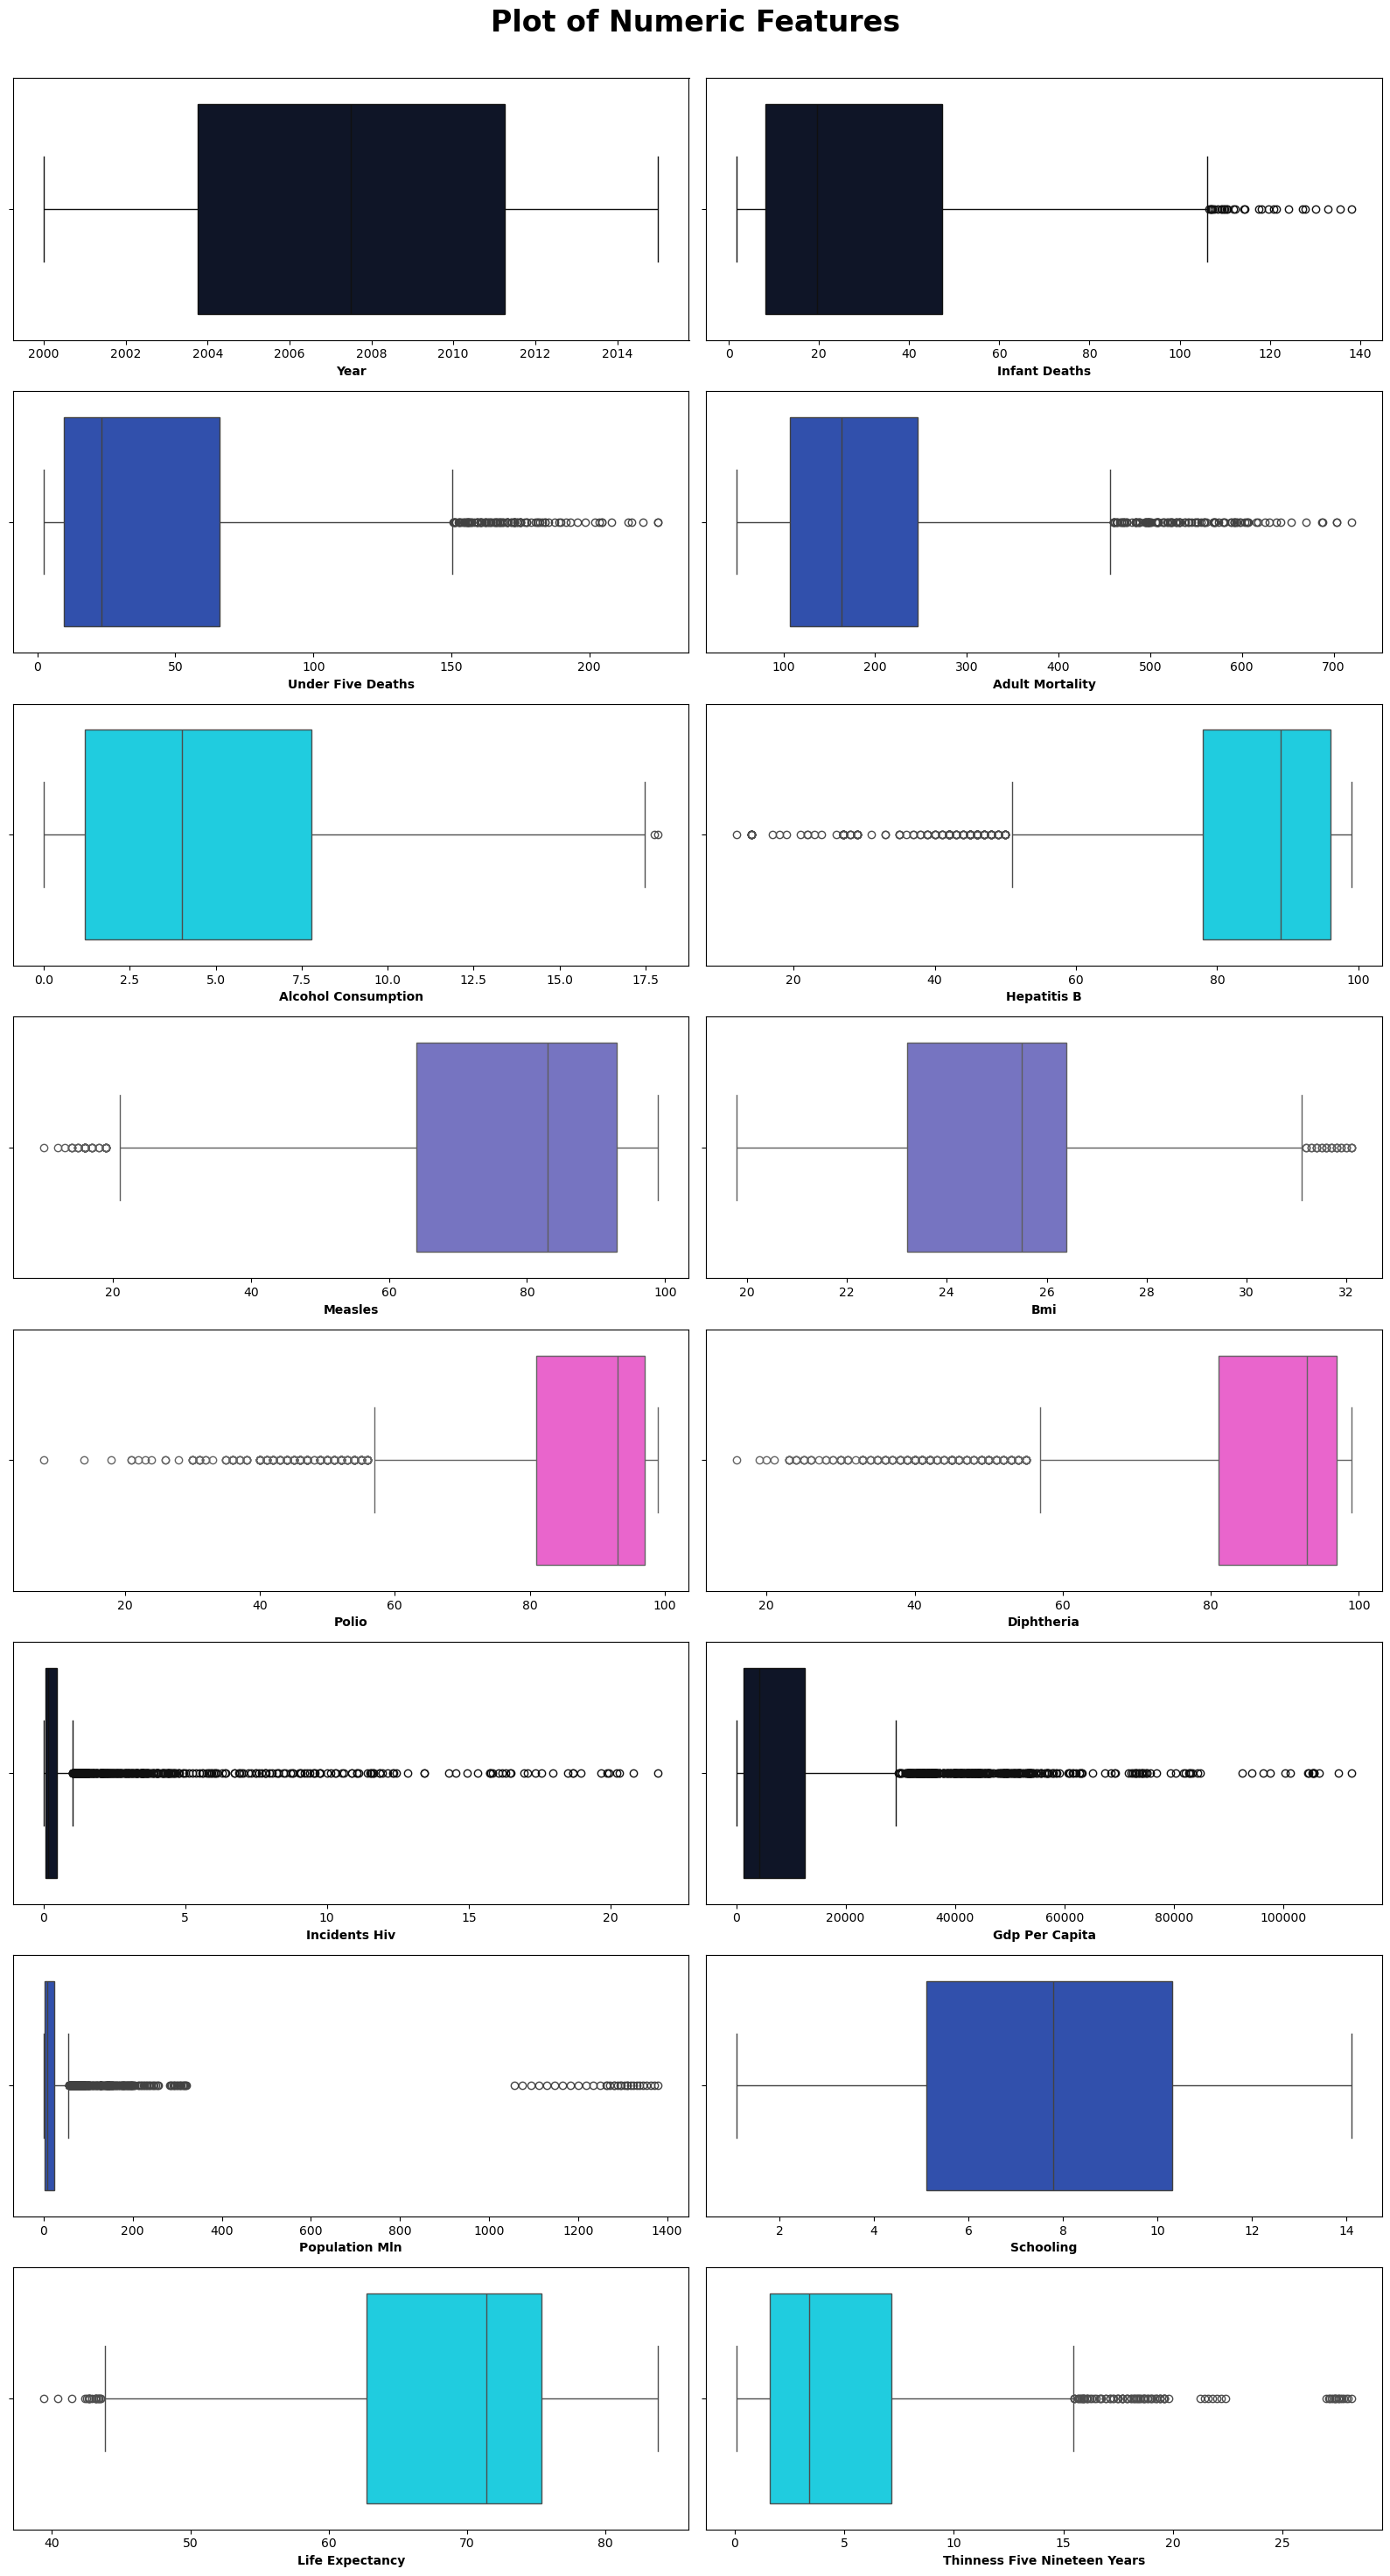

In [494]:
plot_numeric_boxplots(df, numeric_columns)

### Winsorisation -- outlier capping

In [495]:
def cap_outliers(df, numeric_columns):
    df_clean = df.copy()

    for column in numeric_columns:
        Q1 = df_clean[column].quantile(0.25)
        Q3 = df_clean[column].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        df_clean[column] = df_clean[column].clip(lower_bound, upper_bound)

    return df_clean

In [496]:
# df = cap_outliers(df, numeric_columns)

In [497]:
df_outliers = df.copy()

In [498]:
df_outliers = cap_outliers(df_outliers, numeric_columns)

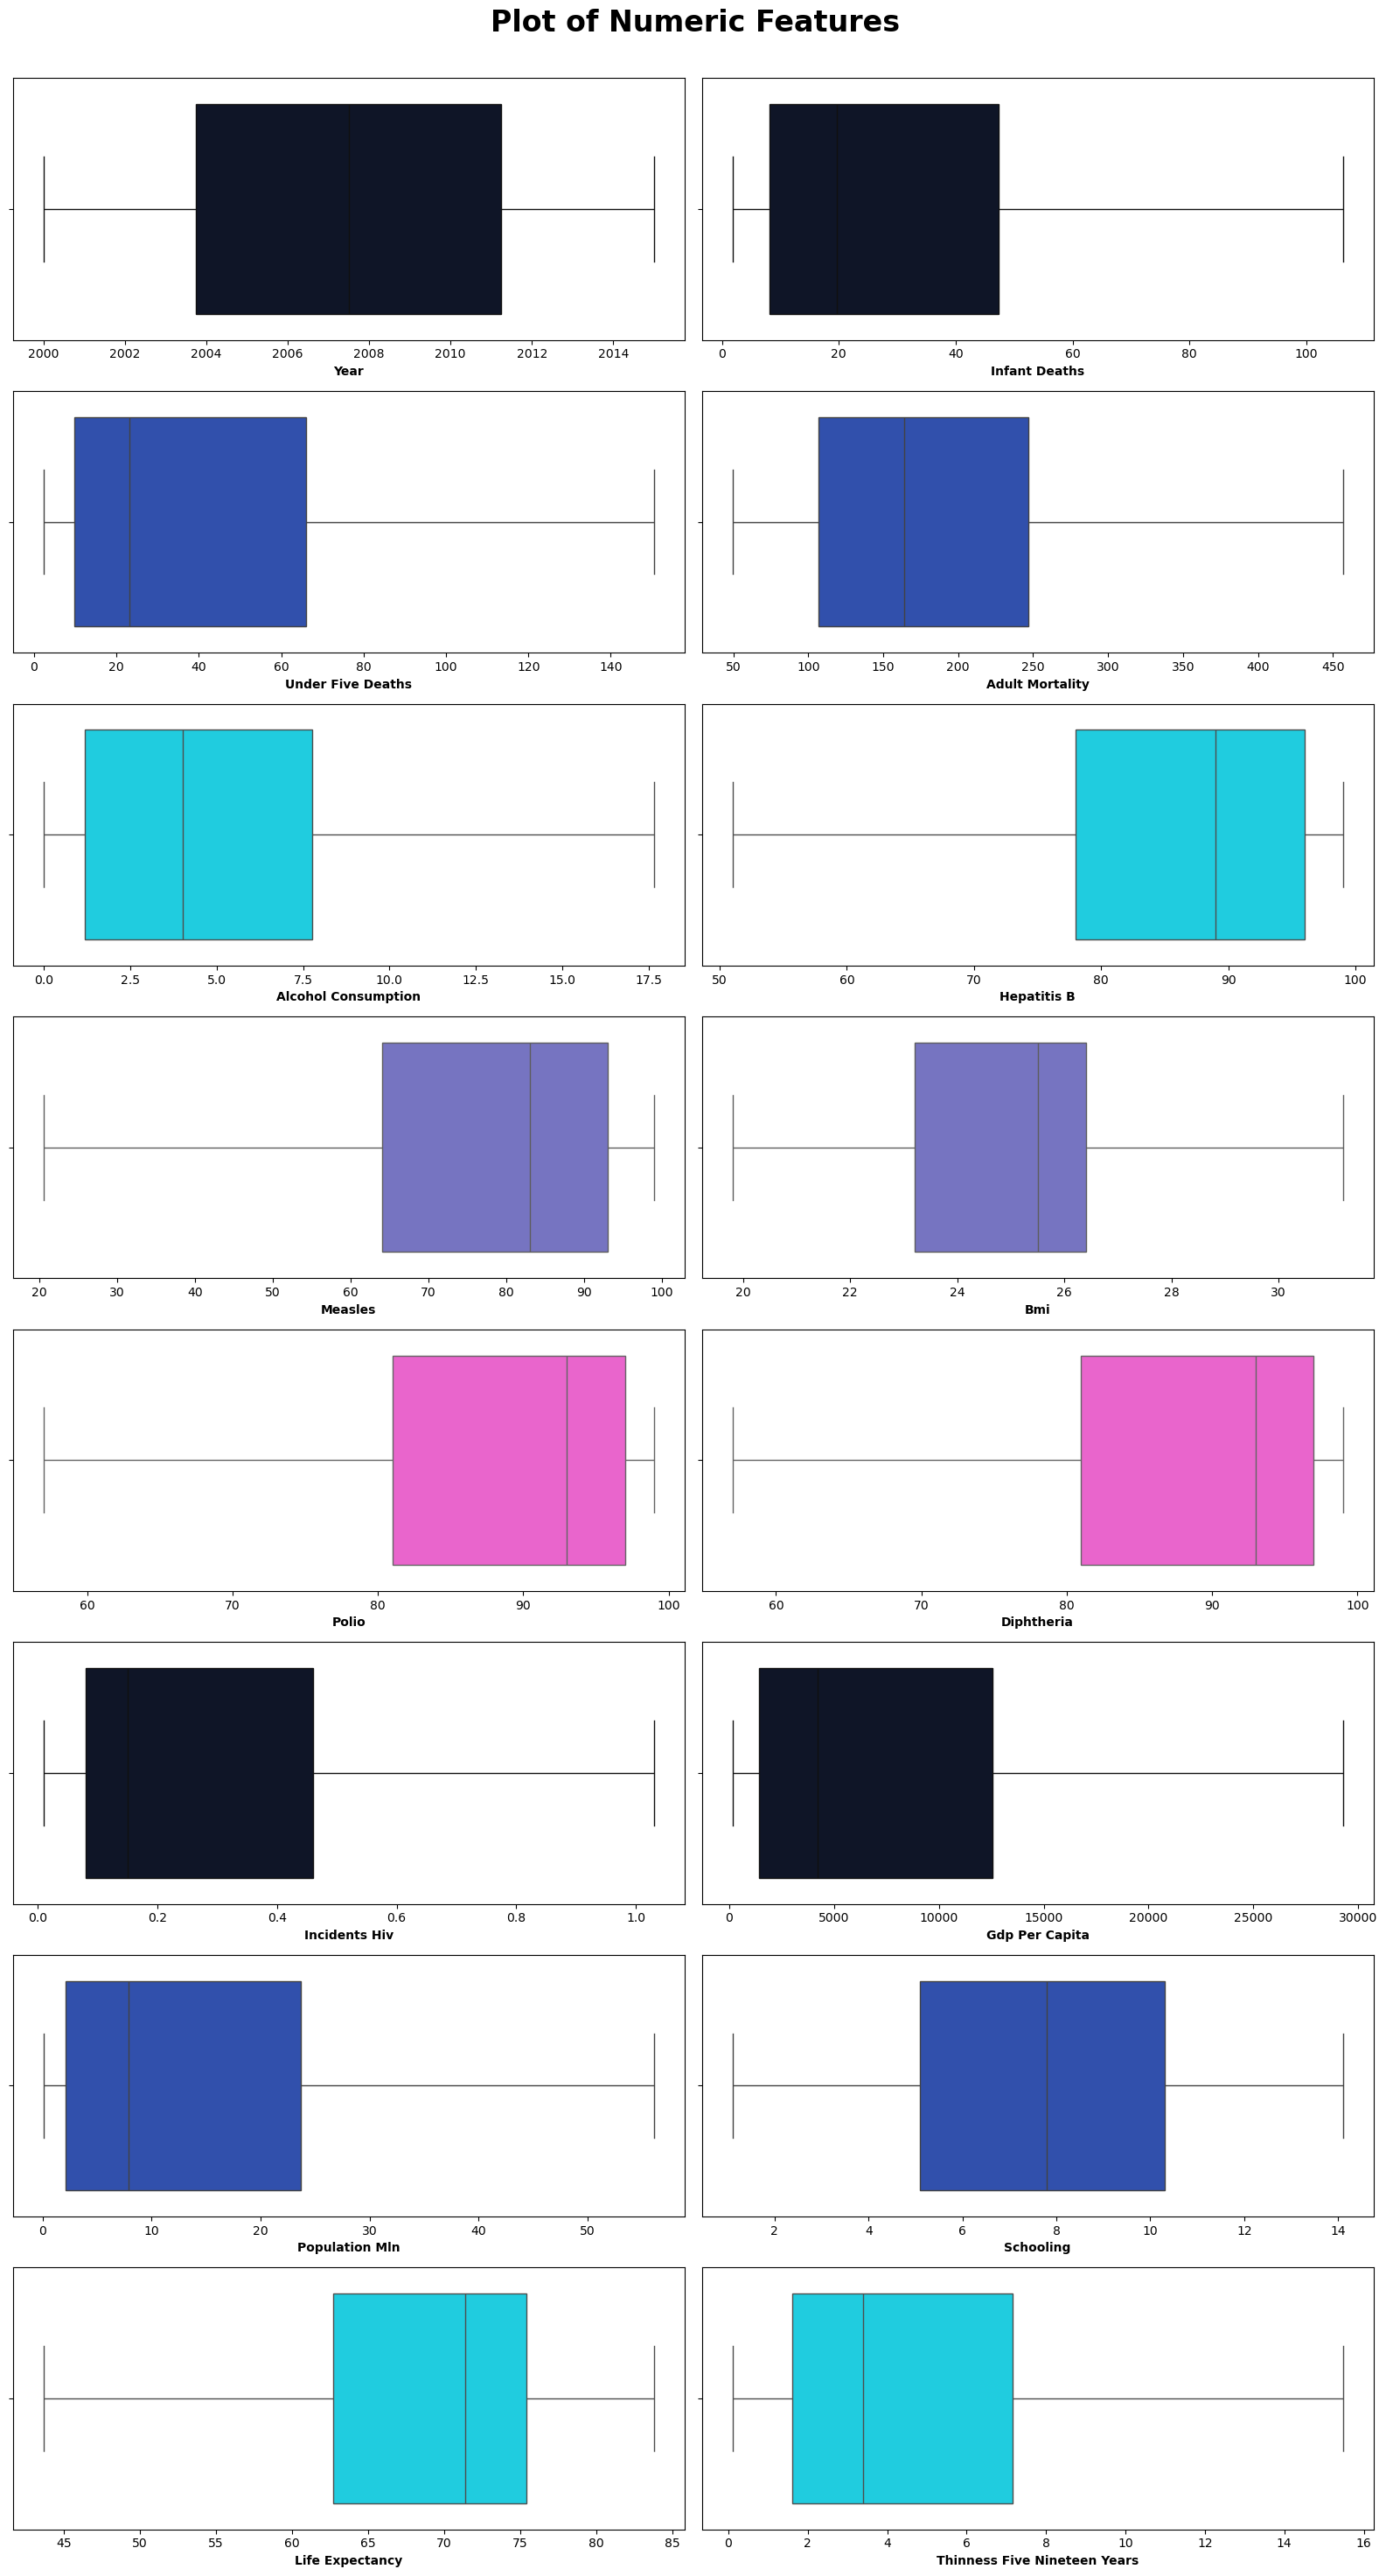

In [499]:
plot_numeric_boxplots(df_outliers, numeric_columns)

## Correlation Heatmap

In [500]:
df_eda = df.copy()
df_eda = df_eda.drop(columns = ["country", "region"])

In [501]:
df_eda.corr()

,year,infant_deaths,under_five_deaths,adult_mortality,alcohol_consumption,hepatitis_b,measles,bmi,polio,diphtheria,incidents_hiv,gdp_per_capita,population_mln,schooling,economic_status,life_expectancy,thinness_five_nineteen_years
year,1.000000e+00,-0.172402,-0.176393,-0.158660,-0.000611,0.176824,0.085945,0.161422,0.139858,0.145143,-0.081743,0.040998,0.015158,0.150539,-5.026601e-15,0.174359,-0.047213
infant_deaths,-1.724017e-01,1.000000,0.985651,0.794661,-0.454526,-0.512562,-0.526282,-0.661988,-0.740790,-0.721875,0.349458,-0.512286,0.007622,-0.788513,-4.758662e-01,-0.920032,0.491940
under_five_deaths,-1.763926e-01,0.985651,1.000000,0.802361,-0.409367,-0.507427,-0.512972,-0.665255,-0.742983,-0.725355,0.369618,-0.469682,-0.005234,-0.773196,-4.271342e-01,-0.920419,0.465978
adult_mortality,-1.586596e-01,0.794661,0.802361,1.000000,-0.244794,-0.344882,-0.416153,-0.522866,-0.524226,-0.513803,0.699119,-0.510121,-0.053848,-0.581035,-4.293748e-01,-0.945360,0.386924
alcohol_consumption,-6.105222e-04,-0.454526,-0.409367,-0.244794,1.000000,0.168436,0.318603,0.284032,0.301926,0.299016,-0.034118,0.443966,-0.039119,0.615728,6.703661e-01,0.399159,-0.446522
hepatitis_b,1.768241e-01,-0.512562,-0.507427,-0.344882,0.168436,1.000000,0.429168,0.345421,0.724345,0.761780,-0.075782,0.159375,-0.082396,0.347643,1.135340e-01,0.417804,-0.214459
measles,8.594472e-02,-0.526282,-0.512972,-0.416153,0.318603,0.429168,1.000000,0.416321,0.514096,0.494059,-0.150580,0.313724,-0.098222,0.498391,2.986933e-01,0.490019,-0.359512
bmi,1.614225e-01,-0.661988,-0.665255,-0.522866,0.284032,0.345421,0.416321,1.000000,0.457206,0.426501,-0.161142,0.336180,-0.166482,0.635475,2.432870e-01,0.598423,-0.607178
polio,1.398584e-01,-0.740790,-0.742983,-0.524226,0.301926,0.724345,0.514096,0.457206,1.000000,0.953178,-0.147952,0.313786,-0.033486,0.552765,2.832601e-01,0.641217,-0.314669
diphtheria,1.451429e-01,-0.721875,-0.725355,-0.513803,0.299016,0.761780,0.494059,0.426501,0.953178,1.000000,-0.146932,0.313321,-0.027336,0.535621,2.894172e-01,0.627541,-0.304690


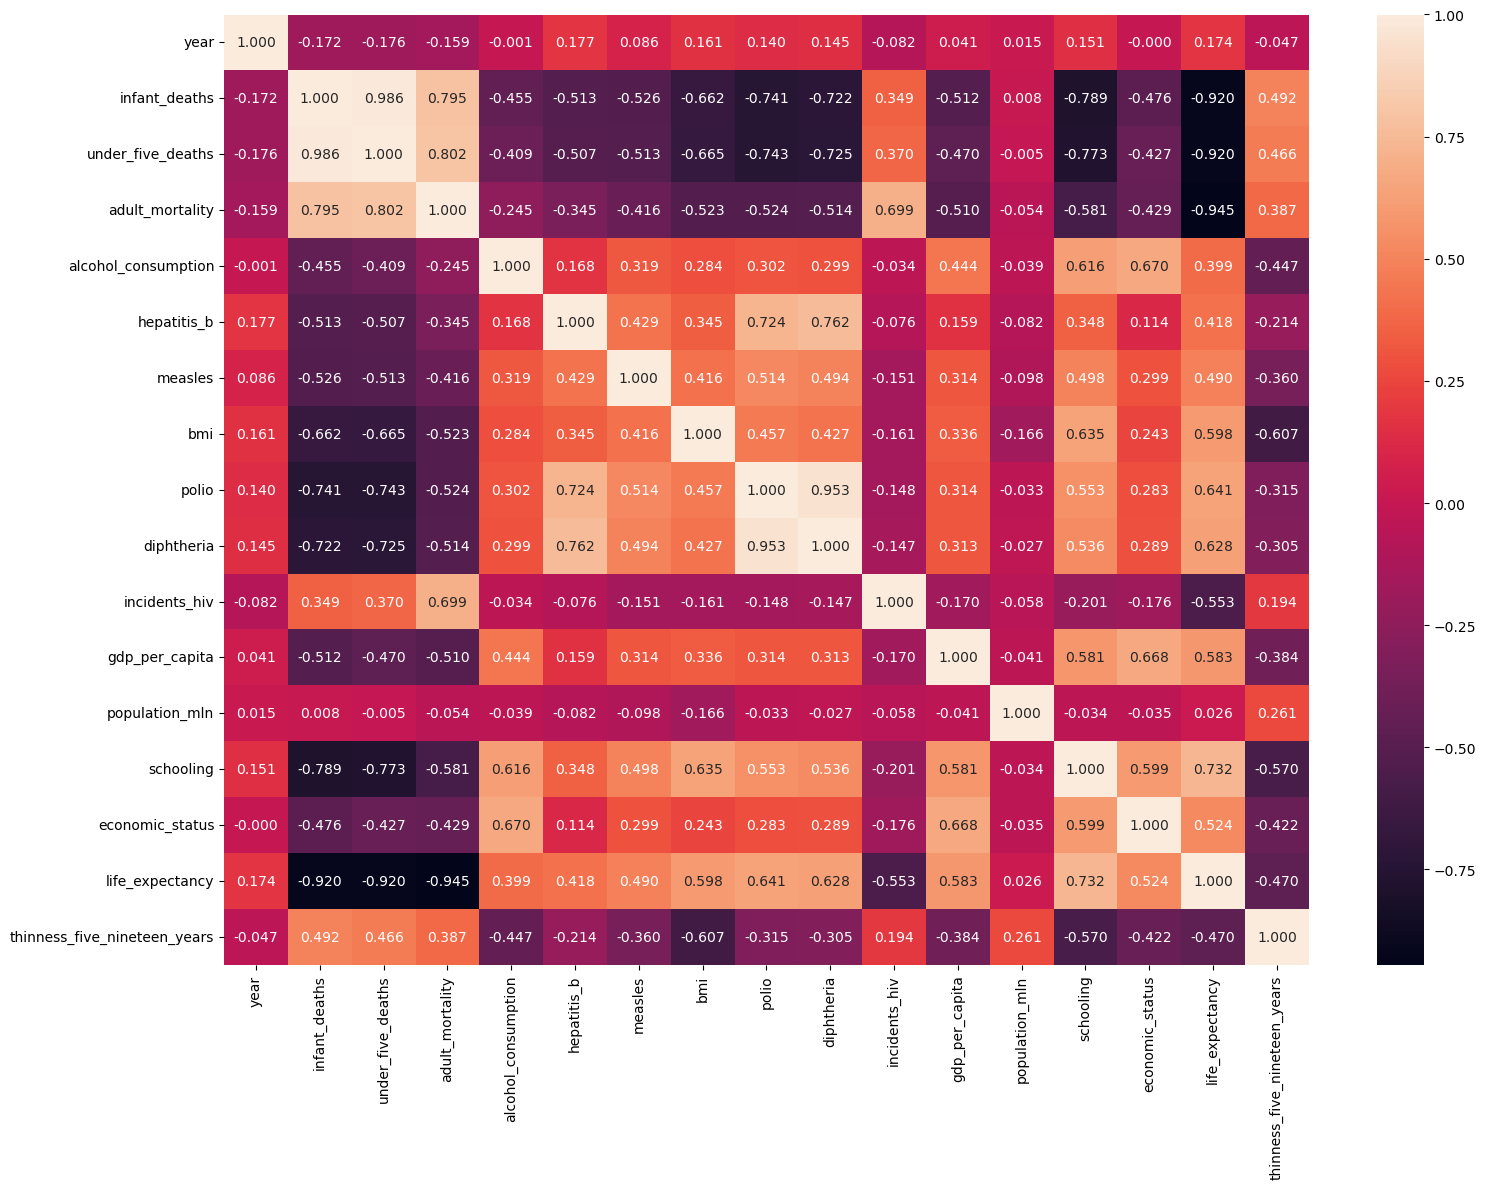

In [502]:
plt.figure(figsize = (16, 12))
sns.heatmap(df_eda.corr(), annot = True, fmt = ".3f")
plt.tight_layout()
plt.show()

## Target Variable Distribution

Text(0.5, 0, 'Life Expectancy')

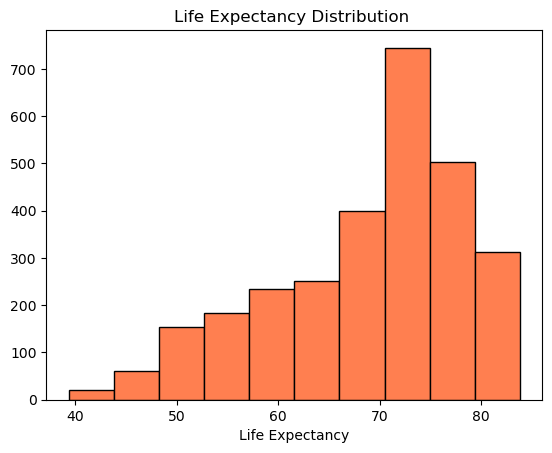

In [503]:
plt.hist(df["life_expectancy"], color= 'coral', edgecolor = "black")
plt.title("Life Expectancy Distribution ")
plt.xlabel("Life Expectancy")

# Feature Selection

## VIF

In [505]:
df.columns.to_list()

['country',
 'region',
 'year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'schooling',
 'economic_status',
 'life_expectancy',
 'thinness_five_nineteen_years']

In [506]:
cols_to_check = [
 'year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'schooling',
 'thinness_five_nineteen_years']

#  'economic_status'

In [507]:
df_with_const = sm.add_constant(df[cols_to_check])

vif_series = pd.Series(
    [
        variance_inflation_factor(df_with_const.values, i)
        for i in range(df_with_const.shape[1])
    ],
    index=df_with_const.columns,
).drop("const")

print(vif_series.sort_values(ascending=False))

under_five_deaths               44.404025
infant_deaths                   44.310561
diphtheria                      12.925926
polio                           11.989451
adult_mortality                  7.624523
schooling                        4.287141
incidents_hiv                    2.888207
bmi                              2.628690
hepatitis_b                      2.587896
thinness_five_nineteen_years     2.069860
gdp_per_capita                   2.014854
alcohol_consumption              1.949284
measles                          1.570191
population_mln                   1.149716
year                             1.069707
dtype: float64


In [508]:
cols_to_drop = vif_series[vif_series > 5].index.to_list()

In [509]:
cols_to_drop

['infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'polio',
 'diphtheria']

In [510]:
# df = df.drop(columns = cols_to_drop)

In [511]:
df.head()

,country,region,year,infant_deaths,under_five_deaths,adult_mortality,alcohol_consumption,hepatitis_b,measles,bmi,polio,diphtheria,incidents_hiv,gdp_per_capita,population_mln,schooling,economic_status,life_expectancy,thinness_five_nineteen_years
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,97,97,0.08,11006,78.53,7.8,0,76.5,4.85
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,97,97,0.09,25742,46.44,9.7,1,82.8,0.55
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,67,64,0.13,1076,1183.21,5.0,0,65.4,27.55
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,92,93,0.79,4146,0.75,7.9,0,67.0,5.60
4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,94,94,0.08,33995,7.91,12.8,1,81.7,1.15


In [512]:
df["region"].unique()

array(['Middle East', 'European Union', 'Asia', 'South America',
       'Central America and Caribbean', 'Rest of Europe', 'Africa',
       'Oceania', 'North America'], dtype=object)

# Preprocessing - Unbound Model

In [513]:
X = df.drop(columns = ["life_expectancy", "country"])
y = df["life_expectancy"]

In [514]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) # test out 0.3 after

## Encoding

In [515]:
X_train_encoded = pd.get_dummies(X_train, columns=["region"], drop_first=True, dtype=int)

X_test_encoded = pd.get_dummies(X_test, columns=["region"], drop_first=True, dtype=int)

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join="left", axis=1, fill_value=0)

## Polynomial Features

In [516]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_encoded)
X_test_poly = poly.transform(X_test_encoded)

feature_names = poly.get_feature_names_out(X_train_encoded.columns)

X_train_encoded_poly = pd.DataFrame(X_train_poly, columns=feature_names, index=X_train_encoded.index)

X_test_encoded_poly = pd.DataFrame(X_test_poly, columns=feature_names, index=X_test_encoded.index)

## Scaling

In [517]:
scaler = StandardScaler()

X_train_encoded_poly_scaled = pd.DataFrame(scaler.fit_transform(X_train_encoded_poly), columns=X_train_encoded_poly.columns, index=X_train_encoded_poly.index)

X_test_encoded_poly_scaled = pd.DataFrame(scaler.transform(X_test_encoded_poly), columns=X_test_encoded_poly.columns, index=X_test_encoded_poly.index)

## Stepwise Selection

In [518]:
def stepwise_selection(X, y, threshold_in=0.01, threshold_out=0.05, verbose=True):
    # The function checks p-values (statistical significance of features) - lower is better
    included = []  # list of features we keep
    while True:
        changed = False

        # forward step: try adding each excluded feature and pick the most significant one
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype='float64')
        for new_column in excluded:
            model = sm.OLS(y, sm.add_constant(pd.DataFrame(X[included + [new_column]]))).fit()
            new_pval[new_column] = model.pvalues[new_column]
        best_pval = new_pval.min()
        # add the feature with the lowest (best) p-value if it's under the threshold
        if best_pval < threshold_in:
            best_feature = new_pval.idxmin()
            included.append(best_feature)
            changed = True
            if verbose:
                print('Add  {:30} with p-value {:.6}'.format(best_feature, best_pval))

        # backward step: drop any feature that became insignificant after the forward step
        model = sm.OLS(y, sm.add_constant(pd.DataFrame(X[included]))).fit()
        # use all coefs except intercept
        pvalues = model.pvalues.iloc[1:]
        worst_pval = pvalues.max()  # null if pvalues is empty
        # if a feature's p-value exceeds the upper threshold, drop it
        if worst_pval > threshold_out:
            changed = True
            worst_feature = pvalues.idxmax()
            included.remove(worst_feature)
            if verbose:
                print('Drop {:30} with p-value {:.6}'.format(worst_feature, worst_pval))

        if not changed:
            break

    return included

In [519]:
selected_features = stepwise_selection(X_train_encoded_poly_scaled, y_train, threshold_in=0.01, threshold_out=0.05, verbose=True)

X_train_final = X_train_encoded_poly_scaled[selected_features]
X_test_final = X_test_encoded_poly_scaled[selected_features]

Add  under_five_deaths measles      with p-value 0.0
Add  adult_mortality polio          with p-value 0.0
Add  under_five_deaths bmi          with p-value 0.0
Add  year polio                     with p-value 1.79464e-206
Add  gdp_per_capita economic_status with p-value 1.0895e-91
Drop under_five_deaths measles      with p-value 0.0757046
Add  measles region_Central America and Caribbean with p-value 1.18297e-43
Add  year adult_mortality           with p-value 8.36676e-48
Add  adult_mortality^2              with p-value 2.70816e-65
Add  alcohol_consumption schooling  with p-value 3.84456e-48
Add  measles region_South America   with p-value 6.62614e-44
Add  alcohol_consumption^2          with p-value 3.17349e-20
Add  incidents_hiv economic_status  with p-value 5.08376e-20
Add  incidents_hiv region_Oceania   with p-value 1.26103e-16
Drop year polio                     with p-value 0.201148
Add  under_five_deaths              with p-value 5.00343e-12
Add  under_five_deaths^2            wit

# Model Training

## Linear Regression - Unbound Model

In [520]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": RidgeCV(
        alphas=[0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0], cv=5
    ),
    "Lasso Regression": LassoCV(cv=5, max_iter=10000, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}


results = []

for name, model in models.items():

    model.fit(X_train_final, y_train)

    # Predict on train and test
    y_train_pred = model.predict(X_train_final)
    y_test_pred = model.predict(X_test_final)

    # Calculate metrics
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    train_rmse = root_mean_squared_error(y_train, y_train_pred)
    test_rmse = root_mean_squared_error(y_test, y_test_pred)

    # Store metrics in a dictionary
    results.append(
        {
            "Model": name,
            "Train R²": round(train_r2, 4),
            "Test R²": round(test_r2, 4),
            "Train MSE": round(train_mse, 4),
            "Test MSE": round(test_mse, 4),
            "Train RMSE": round(train_rmse, 4),
            "Test RMSE": round(test_rmse, 4),
        }
    )

# 3. Convert results list into a comparison DataFrame
results_df = pd.DataFrame(results)

# Sort by Test RMSE (lowest/best first)
results_df = results_df.sort_values(by="Test RMSE").reset_index(drop=True)

# Display the summary table
print("Model Performance Summary without winsorisation:\n")
display(results_df)

Model Performance Summary without winsorisation:



,Model,Train R²,Test R²,Train MSE,Test MSE,Train RMSE,Test RMSE
0,Random Forest,0.9995,0.9973,0.0416,0.2270,0.2040,0.4764
1,Linear Regression,0.9947,0.9930,0.4777,0.5806,0.6912,0.7619
2,Ridge Regression,0.9946,0.9930,0.4804,0.5846,0.6931,0.7646
3,Lasso Regression,0.9916,0.9902,0.7501,0.8134,0.8661,0.9019


Model Performance Summary with winsorisation:

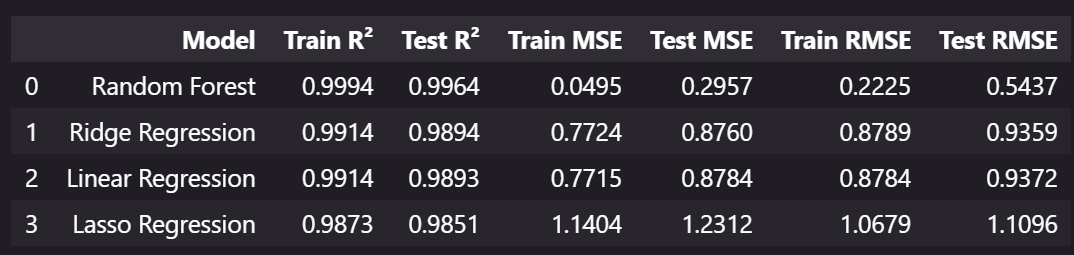

### Pickling

In [521]:
try:
    with open("models_unbound.pkl", "wb") as f:
        pickle.dump(models, f)
    
    saved_models = ", ".join(models.keys())
    print(f"The following models have been saved:\n{saved_models}")

except Exception as e:
    print(f"Model save failed: {e}")

The following models have been saved:
Linear Regression, Ridge Regression, Lasso Regression, Random Forest


# Preprocessing - Bound Model

In [522]:
df_sensitive.head()

,country,region,year,infant_deaths,under_five_deaths,adult_mortality,alcohol_consumption,hepatitis_b,measles,bmi,...,diphtheria,incidents_hiv,gdp_per_capita,population_mln,thinness_ten_nineteen_years,thinness_five_nine_years,schooling,economic_status,economy_status_developing,life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


## Dropping sensitive columns

In [523]:
sensitive_columns = ['Country', 'Infant_deaths', 'Under_five_deaths',
       'Adult_mortality', 'Alcohol_consumption', 'Hepatitis_B', 'Measles',
       'BMI', 'Polio', 'Diphtheria', 'Incidents_HIV', 
        'Thinness_ten_nineteen_years',
       'Thinness_five_nine_years', 'Economy_Status_Developing']

In [524]:
sensitive_columns = [x.lower().strip() for x in sensitive_columns]

In [525]:
print(sensitive_columns)

['country', 'infant_deaths', 'under_five_deaths', 'adult_mortality', 'alcohol_consumption', 'hepatitis_b', 'measles', 'bmi', 'polio', 'diphtheria', 'incidents_hiv', 'thinness_ten_nineteen_years', 'thinness_five_nine_years', 'economy_status_developing']


In [526]:
df_sensitive = df_sensitive.drop(columns = sensitive_columns)

In [527]:
df_sensitive.columns.tolist()

['region',
 'year',
 'gdp_per_capita',
 'population_mln',
 'schooling',
 'economic_status',
 'life_expectancy']

## Train Test Split

In [528]:
X_sen = df_sensitive.drop(columns = ["life_expectancy"])
y_sen = df_sensitive["life_expectancy"]

In [529]:
X_train_sen, X_test_sen, y_train_sen, y_test_sen = train_test_split(X_sen, y_sen, test_size = 0.2, random_state = 42)

## Encoding

In [530]:
X_train_sen_encoded = pd.get_dummies(X_train_sen, columns=["region"], drop_first=True, dtype=int)

X_test_sen_encoded = pd.get_dummies(X_test_sen, columns=["region"], drop_first=True, dtype=int)

X_train_sen_encoded, X_test_sen_encoded = X_train_sen_encoded.align(X_test_sen_encoded, join="left", axis=1, fill_value=0)

In [531]:
poly_sen = PolynomialFeatures(degree=2, include_bias=False)

X_train_sen_poly = poly_sen.fit_transform(X_train_sen_encoded)
X_test_sen_poly = poly_sen.transform(X_test_sen_encoded)

feature_names_sen = poly_sen.get_feature_names_out(X_train_sen_encoded.columns)

X_train_sen_encoded_poly = pd.DataFrame(X_train_sen_poly, columns=feature_names_sen, index=X_train_sen_encoded.index)

X_test_sen_encoded_poly = pd.DataFrame(X_test_sen_poly, columns=feature_names_sen, index=X_test_sen_encoded.index)

In [532]:
scaler_sen = StandardScaler()

X_train_sen_encoded_poly_scaled = pd.DataFrame(scaler_sen.fit_transform(X_train_sen_encoded_poly), columns=X_train_sen_encoded_poly.columns, index=X_train_sen_encoded_poly.index)

X_test_sen_encoded_poly_scaled = pd.DataFrame(scaler_sen.transform(X_test_sen_encoded_poly), columns=X_test_sen_encoded_poly.columns, index=X_test_sen_encoded_poly.index)

## Stepwise Selection

In [533]:
selected_features_sen = stepwise_selection(X_train_sen_encoded_poly_scaled, y_train_sen, threshold_in=0.01, threshold_out=0.05, verbose=True)

X_train_sen_final = X_train_sen_encoded_poly_scaled[selected_features_sen]
X_test_sen_final = X_test_sen_encoded_poly_scaled[selected_features_sen]

Add  year schooling                 with p-value 0.0
Add  year gdp_per_capita            with p-value 4.56557e-44
Add  gdp_per_capita schooling       with p-value 1.21616e-45
Add  population_mln region_Central America and Caribbean with p-value 8.70993e-24
Add  gdp_per_capita^2               with p-value 2.55828e-19
Add  region_South America^2         with p-value 1.40809e-18
Add  year region_Asia               with p-value 1.61624e-24
Add  schooling region_Asia          with p-value 2.65149e-27
Add  region_South America           with p-value 4.33768e-24
Add  year^2                         with p-value 1.50939e-18
Add  gdp_per_capita economic_status with p-value 1.48986e-16
Add  region_Middle East^2           with p-value 2.56819e-20
Add  region_Central America and Caribbean^2 with p-value 5.49459e-27
Add  region_Middle East             with p-value 4.78047e-31
Add  region_Central America and Caribbean with p-value 5.49459e-27
Add  region_Rest of Europe          with p-value 3.35957e-

# Model Training

## Linear Regression - Unbound Model

In [534]:
models_sen= {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": RidgeCV(
        alphas=[0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0], cv=5
    ),
    "Lasso Regression": LassoCV(cv=5, max_iter=10000, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}


results_sen = []

for name, model in models_sen.items():

    model.fit(X_train_sen_final, y_train_sen)

    # Predict on train and test
    y_train_sen_pred = model.predict(X_train_sen_final)
    y_test_sen_pred = model.predict(X_test_sen_final)

    # Calculate metrics
    train_r2_sen = r2_score(y_train_sen, y_train_sen_pred)
    test_r2_sen = r2_score(y_test_sen, y_test_sen_pred)

    train_mse_sen = mean_squared_error(y_train_sen, y_train_sen_pred)
    test_mse_sen = mean_squared_error(y_test_sen, y_test_sen_pred)

    train_rmse_sen = root_mean_squared_error(y_train_sen, y_train_sen_pred)
    test_rmse_sen = root_mean_squared_error(y_test_sen, y_test_sen_pred)

    # Store metrics in a dictionary
    results_sen.append(
        {
            "Model": name,
            "Train R²": round(train_r2_sen, 4),
            "Test R²": round(test_r2_sen, 4),
            "Train MSE": round(train_mse_sen, 4),
            "Test MSE": round(test_mse_sen, 4),
            "Train RMSE": round(train_rmse_sen, 4),
            "Test RMSE": round(test_rmse_sen, 4),
        }
    )

# 3. Convert results list into a comparison DataFrame
results_df_sensitive = pd.DataFrame(results_sen)

# Sort by Test RMSE (lowest/best first)
results_df_sensitive = results_df_sensitive.sort_values(by="Test RMSE").reset_index(drop=True)

# Display the summary table
print("Model Performance Summary:\n")
display(results_df_sensitive)

Model Performance Summary:



,Model,Train R²,Test R²,Train MSE,Test MSE,Train RMSE,Test RMSE
0,Random Forest,0.9877,0.8945,1.1039,8.7576,1.0507,2.9593
1,Ridge Regression,0.8008,0.7498,17.8802,20.7614,4.2285,4.5565
2,Linear Regression,0.8009,0.7496,17.8743,20.7809,4.2278,4.5586
3,Lasso Regression,0.7971,0.7487,18.2158,20.8577,4.2680,4.5670


### Pickling

In [535]:
try:
    with open("models_bound.pkl", "wb") as f:
        pickle.dump(models_sen, f)
    
    saved_models = ", ".join(models_sen.keys())
    print(f"The following models have been saved:\n{saved_models}")

except Exception as e:
    print(f"Model save failed: {e}")

The following models have been saved:
Linear Regression, Ridge Regression, Lasso Regression, Random Forest
